# T3 - Explicabilidad y aprendizaje latente
Responde a dos preguntas del profesor (Issue #1):
1. ¿Cómo mejorar el R² ~ 0,80 de la regresión lineal? -> representaciones latentes (PCA y autoencoder).
2. ¿Cómo explicar los resultados sabiendo que existen permutaciones? -> importancia por
   permutación AGRUPADA, evaluada en datos de prueba agrupados por mezcla y repetida con
   varios modelos y semillas (estabilidad del marco VDS).

Requiere haber ejecutado antes src/eda_t2.py (usa data/processed/concreto_limpio.csv).

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

RAIZ = Path("..")
PROC = RAIZ / "data" / "processed"
FIGS = RAIZ / "docs" / "figuras_t3"
FIGS.mkdir(parents=True, exist_ok=True)
resultados = {}

df = pd.read_csv(PROC / "concreto_limpio.csv")
BASE = ["cemento", "escoria", "ceniza", "agua", "superplast", "grueso", "fino", "edad"]
EXT = BASE + ["a_c", "a_aglom", "prop_adiciones", "pasta_agregados", "log_edad"]
X, y, grupos = df[EXT], df["fc"].values, df["grupo"].values
print(f"{len(df)} filas, {df['grupo'].nunique()} mezclas")

1005 filas, 428 mezclas


## 1. Importancia por permutación AGRUPADA

**Idea simple:** si "barajamos" una variable en los datos de prueba y el R² baja mucho,
el modelo dependía de ella.

**Problema (lo que preguntó el profesor):** agua, cemento y agua/cemento están muy
correlacionadas. Si barajamos solo una, el modelo se apoya en las otras y la importancia
se subestima o se reparte de forma arbitraria.

**Solución:** barajar *juntas* las variables que miden lo mismo (con la misma permutación
de filas, para no romper la relación interna entre ellas), medir la caída del R² solo en
datos de prueba (GroupKFold por mezcla) y repetir con varios modelos y semillas.

In [2]:
GRUPOS_VAR = {
    "Relación agua-cementante": ["agua", "cemento", "a_c", "a_aglom", "pasta_agregados"],
    "Adiciones (escoria, ceniza)": ["escoria", "ceniza", "prop_adiciones"],
    "Superplastificante": ["superplast"],
    "Agregados (grueso, fino)": ["grueso", "fino"],
    "Edad": ["edad", "log_edad"],
}


def modelos(semilla):
    return {
        "Random Forest": RandomForestRegressor(n_estimators=300, random_state=semilla, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(random_state=semilla),
        "MLP": make_pipeline(StandardScaler(),
                             MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=3000,
                                          random_state=semilla)),
    }


def caida_r2(modelo, Xt, yt, columnas, rng, repeticiones=10):
    """Caída media del R² al barajar JUNTAS las columnas indicadas."""
    base = r2_score(yt, modelo.predict(Xt))
    caidas = []
    for _ in range(repeticiones):
        Xp = Xt.copy()
        idx = rng.permutation(len(Xp))          # misma permutación para todo el grupo
        Xp[columnas] = Xt[columnas].values[idx]
        caidas.append(base - r2_score(yt, modelo.predict(Xp)))
    return float(np.mean(caidas))


filas = []
SEMILLAS = [0, 1, 2]
for semilla in SEMILLAS:
    rng = np.random.default_rng(semilla)
    # Se desordenan las mezclas para que cada semilla genere pliegues distintos
    orden_g = rng.permutation(np.unique(grupos))
    mapa = {g: i for i, g in enumerate(orden_g)}
    g_perm = np.array([mapa[g] for g in grupos])
    for tr, te in GroupKFold(n_splits=5).split(X, y, g_perm):
        for nombre, modelo in modelos(semilla).items():
            modelo.fit(X.iloc[tr], y[tr])
            Xt, yt = X.iloc[te], y[te]
            # a) importancia por GRUPO de variables
            for g, cols in GRUPOS_VAR.items():
                filas.append(dict(semilla=semilla, modelo=nombre, tipo="grupo", variable=g,
                                  caida=caida_r2(modelo, Xt, yt, cols, rng)))
            # b) importancia INDIVIDUAL (para mostrar la dilución por correlación)
            for c in ["agua", "cemento", "a_c", "a_aglom", "edad"]:
                filas.append(dict(semilla=semilla, modelo=nombre, tipo="individual", variable=c,
                                  caida=caida_r2(modelo, Xt, yt, [c], rng)))

imp = pd.DataFrame(filas)
tabla = (imp[imp.tipo == "grupo"].groupby(["variable", "modelo"]).caida.mean()
         .unstack().round(3))
tabla["promedio"] = tabla.mean(axis=1).round(3)
print("Caída de R² al barajar cada GRUPO (mayor = más importante):")
print(tabla.sort_values("promedio", ascending=False))

indiv = imp[imp.tipo == "individual"].groupby(["variable", "modelo"]).caida.mean().unstack().round(3)
print("\nImportancia INDIVIDUAL (se diluye por la correlación entre variables):")
print(indiv)

Caída de R² al barajar cada GRUPO (mayor = más importante):
modelo                       Gradient Boosting    MLP  Random Forest  promedio
variable                                                                      
Relación agua-cementante                 0.964  1.270          0.963     1.066
Edad                                     0.772  0.797          0.810     0.793
Adiciones (escoria, ceniza)              0.036  0.245          0.038     0.106
Agregados (grueso, fino)                 0.011  0.109          0.012     0.044
Superplastificante                       0.007  0.026          0.009     0.014

Importancia INDIVIDUAL (se diluye por la correlación entre variables):
modelo    Gradient Boosting    MLP  Random Forest
variable                                         
a_aglom               0.429  0.356          0.529
a_c                   0.102  0.778          0.075
agua                  0.019  0.134          0.004
cemento               0.013  0.023          0.019
edad           

### ¿Es estable el orden de importancia entre modelos?
Correlación de rangos (Spearman) entre las importancias de cada par de modelos.
Valores cercanos a 1 = los modelos coinciden en qué variables importan.

{'Gradient Boosting vs MLP': 1.0, 'Gradient Boosting vs Random Forest': 1.0, 'MLP vs Random Forest': 1.0}

Desviación estándar entre semillas (menor = más estable):
modelo                       Gradient Boosting    MLP  Random Forest
variable                                                            
Adiciones (escoria, ceniza)              0.003  0.027          0.002
Agregados (grueso, fino)                 0.004  0.027          0.002
Edad                                     0.002  0.015          0.007
Relación agua-cementante                 0.019  0.052          0.012
Superplastificante                       0.001  0.010          0.001


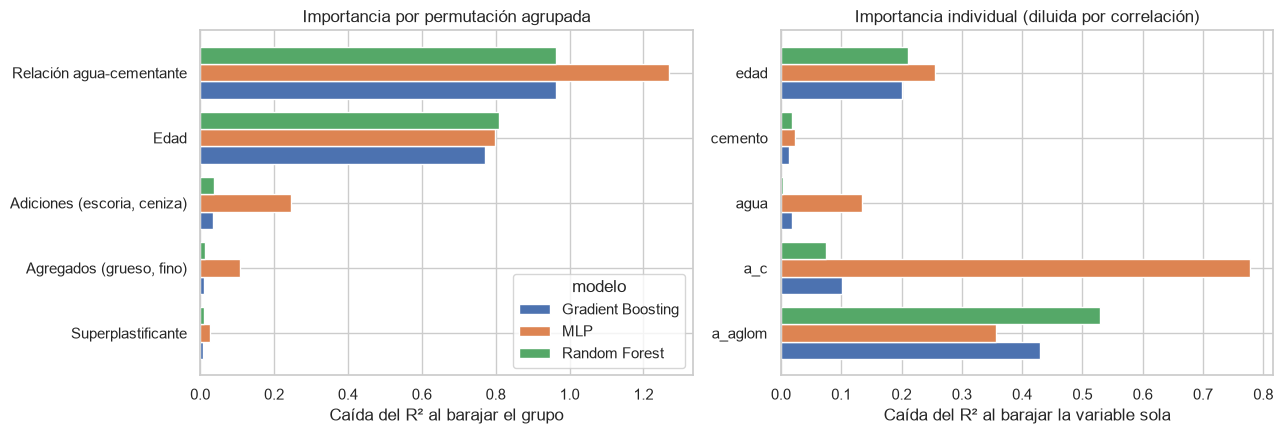

In [3]:
rangos = tabla.drop(columns="promedio")
est = {}
nombres = list(rangos.columns)
for i in range(len(nombres)):
    for j in range(i + 1, len(nombres)):
        r = spearmanr(rangos[nombres[i]], rangos[nombres[j]]).statistic
        est[f"{nombres[i]} vs {nombres[j]}"] = round(float(r), 3)
print(est)

sd = (imp[imp.tipo == "grupo"].groupby(["variable", "modelo", "semilla"]).caida.mean()
      .groupby(["variable", "modelo"]).std().unstack().round(3))
print("\nDesviación estándar entre semillas (menor = más estable):")
print(sd)

resultados["importancia_grupos"] = tabla.to_dict()
resultados["importancia_individual"] = indiv.to_dict()
resultados["estabilidad_rangos_spearman"] = est

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
orden = tabla.sort_values("promedio").index
tabla.loc[orden].drop(columns="promedio").plot.barh(ax=axes[0], width=0.8)
axes[0].set_xlabel("Caída del R² al barajar el grupo")
axes[0].set_ylabel("")
axes[0].set_title("Importancia por permutación agrupada")
indiv.plot.barh(ax=axes[1], width=0.8, legend=False)
axes[1].set_xlabel("Caída del R² al barajar la variable sola")
axes[1].set_ylabel("")
axes[1].set_title("Importancia individual (diluida por correlación)")
fig.tight_layout()
fig.savefig(FIGS / "fig5_importancia_permutacion.png", dpi=150)
plt.show()

## 2. Aprendizaje latente: PCA
Las 8 variables originales están correlacionadas entre sí. El PCA las resume en pocas
"variables latentes" no correlacionadas. Se ajusta DENTRO de cada pliegue (solo con los
datos de entrenamiento) para no filtrar información de la prueba.

In [4]:
def cv_r2(construir, Xdf, semilla_cv=SEED):
    """R² medio en GroupKFold por mezcla; construir() devuelve un modelo nuevo."""
    r2s = []
    for tr, te in GroupKFold(n_splits=5).split(Xdf, y, grupos):
        m = construir()
        m.fit(Xdf.iloc[tr], y[tr])
        r2s.append(r2_score(y[te], m.predict(Xdf.iloc[te])))
    return float(np.mean(r2s)), float(np.std(r2s))


ref_lin = cv_r2(LinearRegression, X)
print(f"Referencia: regresión lineal con 13 variables -> R² {ref_lin[0]:.3f} ± {ref_lin[1]:.3f}")

pca_res = {}
for k in [2, 3, 4, 5, 6, 8]:
    r = cv_r2(lambda k=k: make_pipeline(StandardScaler(), PCA(k, random_state=SEED),
                                        LinearRegression()), df[BASE])
    pca_res[k] = r
    print(f"PCA k={k} (8 variables originales) + lineal -> R² {r[0]:.3f} ± {r[1]:.3f}")

pca_full = make_pipeline(StandardScaler(), PCA(8, random_state=SEED)).fit(df[BASE])
var_exp = pca_full[-1].explained_variance_ratio_
print("Varianza explicada por componente:", np.round(var_exp, 3))
cargas = pd.DataFrame(pca_full[-1].components_[:3].T, index=BASE,
                      columns=["PC1", "PC2", "PC3"]).round(2)
print("\nCargas de los 3 primeros componentes (qué variables forman cada uno):")
print(cargas)

# Con pocas componentes, un modelo LINEAL pierde la no linealidad (p. ej. el efecto de la edad).
# Se repite con Gradient Boosting sobre las componentes para separar "se perdió información"
# de "el modelo lineal no sabe usarla".
pca_gb = {}
for k in [3, 5, 8]:
    r = cv_r2(lambda k=k: make_pipeline(StandardScaler(), PCA(k, random_state=SEED),
                                        GradientBoostingRegressor(random_state=SEED)), df[BASE])
    pca_gb[k] = r
    print(f"PCA k={k} + Gradient Boosting -> R² {r[0]:.3f} ± {r[1]:.3f}")

resultados["pca_gradient_boosting"] = {str(k): v for k, v in pca_gb.items()}
resultados["lineal_13_variables"] = ref_lin
resultados["pca_lineal"] = {str(k): v for k, v in pca_res.items()}
resultados["pca_varianza_explicada"] = var_exp.round(4).tolist()

Referencia: regresión lineal con 13 variables -> R² 0.806 ± 0.027
PCA k=2 (8 variables originales) + lineal -> R² -0.022 ± 0.020
PCA k=3 (8 variables originales) + lineal -> R² 0.306 ± 0.035
PCA k=4 (8 variables originales) + lineal -> R² 0.309 ± 0.030
PCA k=5 (8 variables originales) + lineal -> R² 0.390 ± 0.036
PCA k=6 (8 variables originales) + lineal -> R² 0.515 ± 0.055
PCA k=8 (8 variables originales) + lineal -> R² 0.574 ± 0.050
Varianza explicada por componente: [0.289 0.179 0.159 0.127 0.121 0.099 0.023 0.004]

Cargas de los 3 primeros componentes (qué variables forman cada uno):
             PC1   PC2   PC3
cemento     0.12 -0.46  0.70
escoria     0.19  0.68  0.10
ceniza     -0.42  0.06 -0.35
agua        0.54  0.14 -0.16
superplast -0.50  0.16  0.37
grueso      0.01 -0.51 -0.47
fino       -0.39 -0.01 -0.04
edad        0.29 -0.15  0.02
PCA k=3 + Gradient Boosting -> R² 0.364 ± 0.023
PCA k=5 + Gradient Boosting -> R² 0.477 ± 0.041
PCA k=8 + Gradient Boosting -> R² 0.735 ± 0.022


## 3. Aprendizaje latente: autoencoder
Una red neuronal que comprime las variables a `k` números (cuello de botella) y trata de
reconstruirlas. Esos `k` números son la representación latente y alimentan al modelo de
resistencia. Se implementa con `MLPRegressor` entrenado para reconstruir su propia entrada,
de modo que no hace falta instalar PyTorch.

In [5]:
from sklearn.base import BaseEstimator, RegressorMixin, clone


class AutoencoderRegresor(BaseEstimator, RegressorMixin):
    """Autoencoder (X -> k -> X) + regresor sobre el espacio latente."""

    def __init__(self, k=4, regresor=None, semilla=SEED):
        self.k, self.regresor, self.semilla = k, regresor, semilla

    def _latente(self, Z):
        a = Z
        # capas del codificador: todas hasta el cuello de botella (índice 1)
        W, b = self.ae_.coefs_, self.ae_.intercepts_
        for i in range(2):
            a = a @ W[i] + b[i]
            a = np.maximum(a, 0) if i < 1 else a   # ReLU en oculta, lineal en el cuello
        return a

    def fit(self, Xd, yd):
        self.esc_ = StandardScaler().fit(Xd)
        Z = self.esc_.transform(Xd)
        self.ae_ = MLPRegressor(hidden_layer_sizes=(16, self.k, 16), max_iter=3000,
                                random_state=self.semilla).fit(Z, Z)
        self.reg_ = LinearRegression() if self.regresor is None else clone(self.regresor)
        self.reg_.fit(self._latente(Z), yd)
        return self

    def predict(self, Xd):
        return self.reg_.predict(self._latente(self.esc_.transform(Xd)))


ae_res = {}
for k in [3, 4, 6]:
    lin = cv_r2(lambda k=k: AutoencoderRegresor(k=k), df[BASE])
    gb = cv_r2(lambda k=k: AutoencoderRegresor(
        k=k, regresor=GradientBoostingRegressor(random_state=SEED)), df[BASE])
    ae_res[k] = {"lineal": lin, "gradient_boosting": gb}
    print(f"Autoencoder k={k} + lineal -> R² {lin[0]:.3f} ± {lin[1]:.3f} | "
          f"+ Gradient Boosting -> R² {gb[0]:.3f} ± {gb[1]:.3f}")

resultados["autoencoder"] = {str(k): v for k, v in ae_res.items()}

Autoencoder k=3 + lineal -> R² 0.159 ± 0.067 | + Gradient Boosting -> R² 0.336 ± 0.035
Autoencoder k=4 + lineal -> R² 0.354 ± 0.088 | + Gradient Boosting -> R² 0.407 ± 0.132
Autoencoder k=6 + lineal -> R² 0.402 ± 0.087 | + Gradient Boosting -> R² 0.583 ± 0.043


## 4. Latente SUPERVISADO: PLS y MLP
PCA y el autoencoder comprimen mirando solo las entradas: pueden descartar justo la
dirección que predice la resistencia. PLS (mínimos cuadrados parciales) construye las
variables latentes mirando también la resistencia. El MLP aprende su propia representación
interna (capas ocultas) optimizada para predecir f'c.

In [6]:
from sklearn.cross_decomposition import PLSRegression

pls_res = {}
for k in [3, 5]:
    pls_res[k] = cv_r2(lambda k=k: make_pipeline(StandardScaler(), PLSRegression(k)), X)
    print(f"PLS k={k} (13 variables) -> R² {pls_res[k][0]:.3f} ± {pls_res[k][1]:.3f}")

mlp_res = cv_r2(lambda: make_pipeline(
    StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3,
                                   max_iter=3000, random_state=SEED)), X)
print(f"MLP (64, 32), sin ajuste fino -> R² {mlp_res[0]:.3f} ± {mlp_res[1]:.3f}")
resultados["pls"] = {str(k): v for k, v in pls_res.items()}
resultados["mlp_64_32"] = mlp_res

PLS k=3 (13 variables) -> R² 0.771 ± 0.033
PLS k=5 (13 variables) -> R² 0.802 ± 0.026
MLP (64, 32), sin ajuste fino -> R² 0.837 ± 0.051


## 5. Resumen comparativo (todo con validación agrupada por mezcla)

                             Modelo    R2    DE
          Lineal, 13 variables (T2) 0.806 0.027
                   PLS k=3 + lineal 0.771 0.033
                   PLS k=5 + lineal 0.802 0.026
                       MLP (64, 32) 0.837 0.051
               PCA 3 comp. + lineal 0.306 0.035
               PCA 5 comp. + lineal 0.390 0.036
    PCA 5 comp. + Gradient Boosting 0.477 0.041
    PCA 8 comp. + Gradient Boosting 0.735 0.022
           Autoencoder k=3 + lineal 0.159 0.067
Autoencoder k=3 + Gradient Boosting 0.336 0.035
           Autoencoder k=4 + lineal 0.354 0.088
Autoencoder k=4 + Gradient Boosting 0.407 0.132
           Autoencoder k=6 + lineal 0.402 0.087
Autoencoder k=6 + Gradient Boosting 0.583 0.043


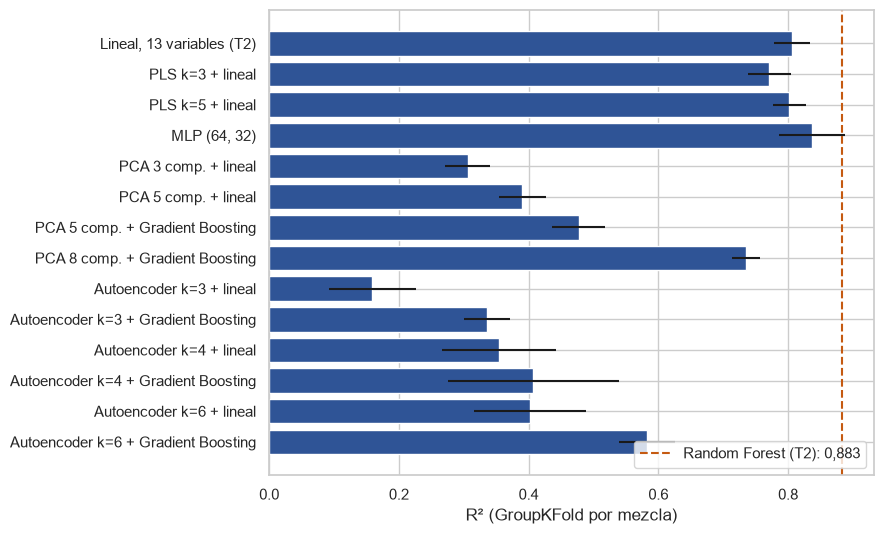

Guardado: ..\data\processed\resultados_t3_explicabilidad.json


In [7]:
resumen = [("Lineal, 13 variables (T2)", *ref_lin)]
resumen += [(f"PLS k={k} + lineal", *v) for k, v in pls_res.items()]
resumen.append(("MLP (64, 32)", *mlp_res))
for k, (m, s) in pca_res.items():
    if k in (3, 5):
        resumen.append((f"PCA {k} comp. + lineal", m, s))
for k, (m, s) in pca_gb.items():
    if k in (5, 8):
        resumen.append((f"PCA {k} comp. + Gradient Boosting", m, s))
for k, d in ae_res.items():
    resumen.append((f"Autoencoder k={k} + lineal", *d["lineal"]))
    resumen.append((f"Autoencoder k={k} + Gradient Boosting", *d["gradient_boosting"]))
res = pd.DataFrame(resumen, columns=["Modelo", "R2", "DE"]).round(3)
print(res.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(res.Modelo[::-1], res.R2[::-1], xerr=res.DE[::-1], color="#2F5496")
ax.axvline(0.883, color="#C55A11", ls="--", label="Random Forest (T2): 0,883")
ax.set_xlabel("R² (GroupKFold por mezcla)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGS / "fig6_latente_comparativo.png", dpi=150)
plt.show()

with open(PROC / "resultados_t3_explicabilidad.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2, default=float)
print("Guardado:", PROC / "resultados_t3_explicabilidad.json")